# Nested Kriging (Gap-Missing): `kdd_cup_2018_with_missing/D`

NaN gaps (sensor outages / calendar holes) are linearly imputed before windowing. The model is otherwise identical to the no-missing procedure: Layer 1 learns ℓ̃(x) via Gaussian MLE per block; Layer 2 runs nested kriging with the Gibbs kernel.

In [1]:
import os, sys
from pathlib import Path

def _find_repo_root() -> Path:
    cwd = Path.cwd().resolve()
    for candidate in [cwd, *cwd.parents]:
        if (candidate / "src").exists() and (candidate / "gift_eval").exists():
            return candidate
    raise RuntimeError("Could not locate KMD_TS repo root.")

REPO_ROOT = _find_repo_root()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
os.environ.setdefault("GIFT_EVAL", str(REPO_ROOT / "GiftEval_data"))
print("Repo root:", REPO_ROOT)

Repo root: /Users/jonghyeonlee/KMD_TS


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from gift_eval.data import Dataset
from src.nested_kriging import (
    LengthscaleField, NestedKrigingForecaster,
    fit_gibbs_lengthscale_field,
    pool_windows_from_series_with_missing,
)

/Users/jonghyeonlee/KMD_TS/ts/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/jonghyeonlee/KMD_TS/ts/lib/python3.12/site-packages/gluonts/json.py:102: UserWarning: Using `json`-module for json-handling. Consider installing one of `orjson`, `ujson` to speed up serialization and deserialization.
  warnings.warn(


In [3]:
DATASET_NAME = "kdd_cup_2018_with_missing/D"
TERM = "short"
TO_UNIVARIATE = False
SERIES_INDEX = 0

MAX_SERIES              = 200
MAX_WINDOWS_PER_SERIES  = 20
MIN_OBSERVED_FRACTION   = 0.5   # min fraction of non-NaN entries in context

CONTEXT_LENGTH = 90
HORIZON_LENGTH = None           # defaults to dataset.prediction_length

NORMALIZATION = "robust_series"

# Layer 1 (lengthscale field)
BLOCK_SIZE_L1    = 80
SIGMA_N_L1       = 0.1
AMPLITUDE_L1     = 1.0
LOG_ELL_LO       = 0.0
LOG_ELL_HI       = 3.4
META_AMPLITUDE   = 1.0
META_BANDWIDTH   = None

# Layer 2 (nested kriging regression)
BLOCK_SIZE_L2 = 100
MAX_BLOCKS_L2 = 30
SIGMA_N_L2    = 0.1
AMPLITUDE_L2  = 1.0

EVALUATE_ALL_SERIES = False
EVAL_SERIES_LIMIT   = None

In [4]:
dataset = Dataset(
    name=DATASET_NAME, term=TERM, to_univariate=TO_UNIVARIATE,
    storage_env_var="GIFT_EVAL",
)
print("dataset_name       :", DATASET_NAME)
print("frequency          :", dataset.freq)
print("prediction_length  :", dataset.prediction_length)
print("test windows/series:", dataset.windows)
print("n_raw_series       :", len(dataset.hf_dataset))
print("target_dim         :", dataset.target_dim)

dataset_name       : kdd_cup_2018_with_missing/D
frequency          : D
prediction_length  : 30
test windows/series: 2
n_raw_series       : 270
target_dim         : 1


In [5]:
def _nth(it, i):
    for j, x in enumerate(it):
        if j == i: return x
    raise IndexError(i)

def _series(entry):
    return np.asarray(entry["target"], dtype=float).reshape(-1)

def _train(i):   return _series(_nth(dataset.training_dataset,    i))
def _val(i):     return _series(_nth(dataset.validation_dataset,   i))
def _test(i, w):
    fi = i * dataset.windows + w
    ctx = _series(_nth(dataset.test_data.input, fi))
    lbl = _series(_nth(dataset.test_data.label, fi))
    return ctx, lbl

def relative_l2(true, pred):
    t, p = np.asarray(true, float).ravel(), np.asarray(pred, float).ravel()
    d = float(np.sum(t**2))
    if d > 1e-12:
        return float(np.sum((t - p) ** 2) / d)
    # Target is all-zero (no demand in window) — fall back to absolute L2
    return float(np.sum((t - p) ** 2))

def _plot(y_true, y_pred, *, title):
    t = np.arange(1, len(y_true)+1)
    plt.figure(figsize=(10,4))
    plt.plot(t, y_true, label="true", lw=2)
    plt.plot(t, y_pred, label="pred",  lw=2)
    plt.title(title); plt.xlabel("step"); plt.legend(); plt.grid(alpha=.25); plt.show()

def _collect_series(split, *, max_s):
    it = dataset.training_dataset if split == "train" else dataset.validation_dataset
    out = []
    for i, entry in enumerate(it):
        if max_s is not None and i >= max_s: break
        out.append(_series(entry))
    return out

def _eval_indices(n_total):
    if not EVALUATE_ALL_SERIES: return [SERIES_INDEX]
    lim = n_total if EVAL_SERIES_LIMIT is None else min(EVAL_SERIES_LIMIT, n_total)
    return list(range(max(1, lim)))

## Layer 1 — Fit Lengthscale Field (training split)

In [6]:
rng = np.random.default_rng(42)
horizon_length = dataset.prediction_length if HORIZON_LENGTH is None else int(HORIZON_LENGTH)

print("Collecting training series …")
train_series = _collect_series("train", max_s=MAX_SERIES)
print(f"  {len(train_series)} series")

print("Pooling windows (with NaN imputation) …")
ctx_train, tgt_train, meta_train = pool_windows_from_series_with_missing(
    train_series,
    context_length=CONTEXT_LENGTH,
    horizon_length=horizon_length,
    stride=horizon_length,
    max_windows_per_series=MAX_WINDOWS_PER_SERIES,
    normalization=NORMALIZATION,
    min_observed_fraction=MIN_OBSERVED_FRACTION,
    rng=rng,
)
print(f"  pooled {ctx_train.shape[0]} windows, shape {ctx_train.shape}")

print("\nFitting Layer 1 (lengthscale field) …")
ell_field = fit_gibbs_lengthscale_field(
    ctx_train, tgt_train,
    block_size_l1=BLOCK_SIZE_L1,
    sigma_n=SIGMA_N_L1,
    amplitude=AMPLITUDE_L1,
    log_ell_bounds=(LOG_ELL_LO, LOG_ELL_HI),
    meta_amplitude=META_AMPLITUDE,
    meta_bandwidth=META_BANDWIDTH,
    rng=rng,
)
print(f"  anchors (M_1): {ell_field.n_anchors}")
print(f"  meta_bandwidth: {ell_field.meta_bandwidth:.4f}")
print(f"  sample ℓ̃: {ell_field.predict_ell(ctx_train[:5]).round(4)}")

  200 series
Pooling windows (with NaN imputation) …
  pooled 1726 windows, shape (1726, 90)

Fitting Layer 1 (lengthscale field) …
  anchors (M_1): 22
  meta_bandwidth: 1.3889
  sample ℓ̃: [1.6487 1.6487 1.6487 1.6488 1.6487]


## Layer 2 — Fit Nested Kriging Regression (training split)

In [7]:
print("Fitting Layer 2 (nested kriging) …")
forecaster = NestedKrigingForecaster(
    ell_field,
    block_size=BLOCK_SIZE_L2,
    max_blocks=MAX_BLOCKS_L2,
    sigma_n=SIGMA_N_L2,
    amplitude=AMPLITUDE_L2,
    rng=rng,
).fit(ctx_train, tgt_train)

sizes = [len(b.indices) for b in forecaster._fitted_blocks]
print(f"  blocks: {len(sizes)}, sizes: min={min(sizes)} max={max(sizes)} mean={np.mean(sizes):.1f}")

Fitting Layer 2 (nested kriging) …
  blocks: 18, sizes: min=26 max=100 mean=95.9


## Short-Term Evaluation: train → validation \ train

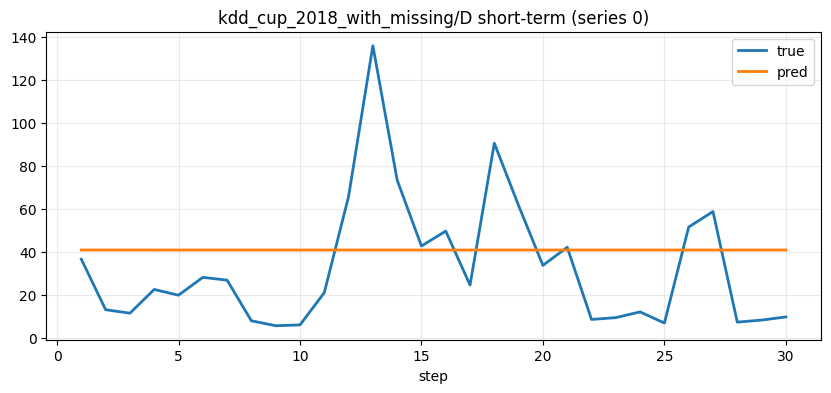

Evaluated: 1, skipped: 0
Mean relL2: 0.477011  Median: 0.477011


In [8]:
horizon_length = dataset.prediction_length if HORIZON_LENGTH is None else int(HORIZON_LENGTH)
n_total = len(dataset.hf_dataset)
errors, skipped, plotted = [], [], False

for idx in _eval_indices(n_total):
    tr = _train(idx);  va = _val(idx)
    extra = va[len(tr):]
    if len(tr) < CONTEXT_LENGTH or len(extra) < horizon_length:
        skipped.append((idx, "too short")); continue

    obs = tr[np.isfinite(tr)]
    if len(obs) < 2: skipped.append((idx, "all NaN train")); continue
    if NORMALIZATION == "robust_series":
        loc = float(np.median(obs))
        q75, q25 = float(np.percentile(obs,75)), float(np.percentile(obs,25))
        scale = max((q75-q25)/1.349, float(np.std(obs)), 1e-6)
    else:
        loc, scale = 0.0, 1.0

    from src.nested_kriging import _linear_impute
    query_raw = tr[-CONTEXT_LENGTH:]
    query_norm = (_linear_impute(query_raw) - loc) / scale
    pred_norm = forecaster.predict(query_norm)
    pred = pred_norm * scale + loc

    true_h = extra[:horizon_length]
    obs_h = np.isfinite(true_h)
    if not obs_h.any(): skipped.append((idx, "all NaN val-extra")); continue
    err = relative_l2(true_h[obs_h], pred.ravel()[:horizon_length][obs_h])
    errors.append(err)

    if (not EVALUATE_ALL_SERIES and idx == SERIES_INDEX) or (EVALUATE_ALL_SERIES and not plotted):
        _plot(true_h, pred.ravel()[:horizon_length],
              title=f"{DATASET_NAME} short-term (series {idx})")
        plotted = True

if errors:
    a = np.asarray(errors, float)
    print(f"Evaluated: {len(errors)}, skipped: {len(skipped)}")
    print(f"Mean relL2: {float(np.nanmean(a)):.6f}  Median: {float(np.nanmedian(a)):.6f}")
else:
    print("No short-term forecasts evaluated."); [print(" ", s) for s in skipped]

## Re-Fit on Validation Split

In [9]:
horizon_length = dataset.prediction_length if HORIZON_LENGTH is None else int(HORIZON_LENGTH)
print("Collecting validation series …")
val_series = _collect_series("validation", max_s=MAX_SERIES)

print("Pooling validation windows …")
ctx_val, tgt_val, meta_val = pool_windows_from_series_with_missing(
    val_series,
    context_length=CONTEXT_LENGTH,
    horizon_length=horizon_length,
    stride=horizon_length,
    max_windows_per_series=MAX_WINDOWS_PER_SERIES,
    normalization=NORMALIZATION,
    min_observed_fraction=MIN_OBSERVED_FRACTION,
    rng=rng,
)
print(f"  {ctx_val.shape[0]} windows")

print("Fitting Layer 1 on validation …")
ell_field_val = fit_gibbs_lengthscale_field(
    ctx_val, tgt_val,
    block_size_l1=BLOCK_SIZE_L1, sigma_n=SIGMA_N_L1, amplitude=AMPLITUDE_L1,
    log_ell_bounds=(LOG_ELL_LO, LOG_ELL_HI),
    meta_amplitude=META_AMPLITUDE, meta_bandwidth=META_BANDWIDTH, rng=rng,
)
print("Fitting Layer 2 on validation …")
forecaster_val = NestedKrigingForecaster(
    ell_field_val, block_size=BLOCK_SIZE_L2, max_blocks=MAX_BLOCKS_L2,
    sigma_n=SIGMA_N_L2, amplitude=AMPLITUDE_L2, rng=rng,
).fit(ctx_val, tgt_val)
print("Done.")

Pooling validation windows …
  1926 windows
Fitting Layer 1 on validation …
Fitting Layer 2 on validation …
Done.


## Long-Term Evaluation: test window 0

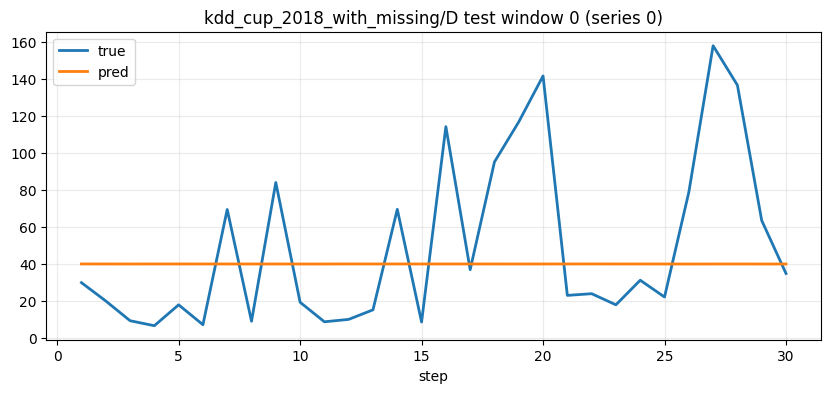

Evaluated: 1, skipped: 0
Mean relL2: 0.475775  Median: 0.475775


In [10]:
horizon_length = dataset.prediction_length if HORIZON_LENGTH is None else int(HORIZON_LENGTH)
n_total = len(dataset.hf_dataset)
errors, skipped, plotted = [], [], False

from src.nested_kriging import _linear_impute
for idx in _eval_indices(n_total):
    va = _val(idx)
    if len(va) < CONTEXT_LENGTH: skipped.append((idx, "val too short")); continue
    obs = va[np.isfinite(va)]
    if len(obs) < 2: skipped.append((idx, "all NaN val")); continue
    if NORMALIZATION == "robust_series":
        loc = float(np.median(obs))
        q75, q25 = float(np.percentile(obs,75)), float(np.percentile(obs,25))
        scale = max((q75-q25)/1.349, float(np.std(obs)), 1e-6)
    else: loc, scale = 0.0, 1.0

    try: ctx_e, lbl_e = _test(idx, 0)
    except IndexError as e: skipped.append((idx, str(e))); continue
    if len(ctx_e) < CONTEXT_LENGTH or len(lbl_e) < horizon_length:
        skipped.append((idx, "test ctx/lbl too short")); continue

    query_raw = ctx_e[-CONTEXT_LENGTH:]
    query_norm = (_linear_impute(query_raw) - loc) / scale
    pred_norm = forecaster_val.predict(query_norm)
    pred = pred_norm * scale + loc

    true_h = lbl_e[:horizon_length]
    obs_h = np.isfinite(true_h)
    if not obs_h.any(): skipped.append((idx, "all NaN test label")); continue
    errors.append(relative_l2(true_h[obs_h], pred.ravel()[:horizon_length][obs_h]))

    if (not EVALUATE_ALL_SERIES and idx == SERIES_INDEX) or (EVALUATE_ALL_SERIES and not plotted):
        _plot(true_h, pred.ravel()[:horizon_length],
              title=f"{DATASET_NAME} test window 0 (series {idx})")
        plotted = True

if errors:
    a = np.asarray(errors, float)
    print(f"Evaluated: {len(errors)}, skipped: {len(skipped)}")
    print(f"Mean relL2: {float(np.nanmean(a)):.6f}  Median: {float(np.nanmedian(a)):.6f}")
else:
    print("No test forecasts evaluated."); [print(" ", s) for s in skipped]

In [11]:
# ── Export model state for cross-dataset nested kriging layer ────────────────
from pathlib import Path
import sys, os; sys.path.insert(0, os.path.join(os.path.dirname(os.getcwd()), ".."))

models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

safe_name = DATASET_NAME.replace("/", "__")
save_path = models_dir / f"{safe_name}.npz"
forecaster.save_state(save_path, dataset_name=DATASET_NAME)
print(f"Saved model state → {save_path}  ({len(forecaster._fitted_blocks)} blocks)")


Saved model state → ../models/kdd_cup_2018_with_missing__D.npz  (18 blocks)
